# 2. Data Understanding: Eksplorasi Sinyal Akustik & Karakteristik Emosi Berbasis Affective Computing

Tahap **Data Understanding** dalam metodologi **CRISP-DM** bertujuan untuk mengaudit struktur, kualitas sinyal fisik, dan karakteristik paralinguistik dari dataset wicara emosional **RAVDESS (*Ryerson Audio-Visual Database of Emotional Speech and Song*)** sebelum memasuki tahap pembersihan data dan pemodelan **Attention-based CRNN**.

Sesuai arahan pada dokumen **Business Understanding (`1-business.md`)**, seluruh analisis pada tahapan ini diselaraskan dengan paradigma **Affective Computing (Komputasi Afektif)** melalui empat fondasi teori psikologi:
1. **Teori Emosi Diskrit Paul Ekman:** Menguji kelayakan 8 kategori emosi universal (*Neutral, Calm, Happy, Sad, Angry, Fearful, Disgust, Surprised*) sebagai label target klasifikasi kategoris.
2. **Model Sirkumpleks James Russell:** Memetakan karakteristik akustik audio ke dalam dua sumbu psikologis utama: *Arousal* (tingkat aktivasi/energi suara) dan *Valence* (kualitas emosi positif vs negatif).
3. **Psikofisiologi Sistem Saraf Otonom (ANS):** Menghubungkan respon fisiologis laring, ketegangan pita suara, dan laju pernapasan dengan parameter fisik audio (RMSE, ZCR, Formants, Spectral Centroid, dan Rolloff).
4. **Validasi Psikometri Persepsi Manusia (Livingstone & Russo, 2018):** Memverifikasi reliabilitas konsistensi *inter-rater* dari 247 penilai manusia independen sebagai jaminan kualitas *ground truth* data sebelum pelatihan model.

### Agenda Kerja Data Understanding:
* **Inventarisasi & Deduplikasi Folder:** Memindai 1.440 file audio kanonik pada folder `Actor_01` s.d. `Actor_24` dan mencegah duplikasi folder cermin arsip Kaggle.
* **Parsing 7-Segmen Metadata:** Mengurai kode nama berkas `03-01-XX-YY-ZZ-RR-AA.wav` menjadi atribut terstruktur.
* **Audit Integritas Sinyal & Ekstraksi Diagnostik:** Memeriksa keterbacaan file, ketiadaan `NaN/Inf`, format kanal (*Mono vs Stereo*), laju cuplik ($48\text{ kHz}$), serta distribusi durasi sebelum dan sesudah *silence trimming* ($25\text{ dB}$).
* **Analisis Ketimpangan Kelas (*Class Imbalance*):** Membuktikan secara kuantitatif ketimpangan kelas minoritas *Neutral* ($96\text{ sampel}$) terhadap 7 kelas lainnya ($192\text{ sampel}$).
* **Verifikasi Partisi Bebas Kebocoran:** Memastikan keseimbangan gender ($12\text{ Pria}$ dan $12\text{ Wanita}$) untuk skema *Speaker-Independent GroupKFold*.
* **Eksplorasi Akustik Multi-Domain:** Membandingkan gelombang waktu (*Waveform*), spektrogram (*Log Mel-Spectrogram 128 Bin*), fitur energi/desis (RMSE, ZCR, Centroid, Rolloff), dan koefisien timbre vokal (MFCC).
* **Penerbitan Artefak Katalog:** Menghasilkan tabel CSV komprehensif `ravdess_data_understanding_catalog.csv` sebagai manifest data terpadu.


In [1]:
import os
import glob
import wave
import warnings
import numpy as np
import pandas as pd
import scipy.io.wavfile as wavfile
import scipy.signal as signal
from scipy.fft import dct
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings('ignore')

# konfigurasi visualisasi dan tampilan tabel data
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (13, 6)
plt.rcParams['font.size'] = 10.5
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'

# inisialisasi direktori dataset dan penyimpanan visualisasi
DATASET_DIR = os.path.join(os.path.dirname(os.path.abspath('__file__')), 'dataset')
OUTPUT_IMAGE_DIR = os.path.join(os.path.dirname(os.path.abspath('__file__')), 'images')
os.makedirs(OUTPUT_IMAGE_DIR, exist_ok=True)

print(f"[OK] pustaka analisis sinyal dan visualisasi berhasil dimuat.")
print(f"[INFO] direktori dataset: {DATASET_DIR}")


[OK] pustaka analisis sinyal dan visualisasi berhasil dimuat.
[INFO] direktori dataset: d:\university\semester 5_book\proyek sain data\src\project_akhir\2-data_understanding\dataset


---
## 2.1 Inventarisasi File, Deduplikasi Direktori, dan Parsing 7-Segmen Metadata

Dataset RAVDESS menggunakan konvensi penamaan berkas terstandarisasi yang memuat 7 segmen kode numerik `03-01-XX-YY-ZZ-RR-AA.wav`:
* **Segmen 1 (`Modality`):** `03` = Audio-only (rekaman audio wicara murni).
* **Segmen 2 (`Vocal Channel`):** `01` = Speech (dialog wicara, bukan instrumen lagu).
* **Segmen 3 (`Emotion`):** `01` = *Neutral*, `02` = *Calm*, `03` = *Happy*, `04` = *Sad*, `05` = *Angry*, `06` = *Fearful*, `07` = *Disgust*, `08` = *Surprised* (8 kelas emosi diskrit Paul Ekman).
* **Segmen 4 (`Emotional Intensity`):** `01` = *Normal*, `02` = *Strong* (derajat intensitas ekspresi afektif).
* **Segmen 5 (`Statement`):** Dua kalimat leksikal identik:
  * `01` = *"Kids are talking by the door"*
  * `02` = *"Dogs are sitting by the door"*
* **Segmen 6 (`Repetition`):** Pengulangan rekaman ke-1 (`01`) dan ke-2 (`02`).
* **Segmen 7 (`Actor ID`):** `01` s.d. `24` (nomor ganjil = 12 aktor pria, nomor genap = 12 aktor wanita).

> **Deduplikasi Direktori:** Arsip unduhan Kaggle memuat folder cermin `audio_speech_actors_01-24` yang berisi salinan persis dari folder `Actor_01` s.d. `Actor_24`. Pipeline ini memindai secara presisi hanya folder `dataset/Actor_*` untuk memastikan data yang diproses tepat 1.440 file audio kanonik bebas duplikasi.


In [2]:
# kamus pemetaan emosi diskrit paul ekman
EMOTION_MAP = {
    '01': 'Neutral',
    '02': 'Calm',
    '03': 'Happy',
    '04': 'Sad',
    '05': 'Angry',
    '06': 'Fearful',
    '07': 'Disgust',
    '08': 'Surprised'
}

# pengelompokan sumbu arousal james russell
AROUSAL_GROUP_MAP = {
    'Angry': 'High Arousal',
    'Surprised': 'High Arousal',
    'Happy': 'High Arousal',
    'Fearful': 'High Arousal',
    'Disgust': 'Medium-Low Arousal',
    'Neutral': 'Low Arousal',
    'Sad': 'Low Arousal',
    'Calm': 'Low Arousal'
}

# kamus atribut intensitas dan kalimat leksikal
INTENSITY_MAP = {'01': 'Normal', '02': 'Strong'}
STATEMENT_MAP = {
    '01': 'Kids are talking by the door',
    '02': 'Dogs are sitting by the door'
}
REPETITION_MAP = {'01': '1st Repetition', '02': '2nd Repetition'}

# pindai berkas kanonik untuk menghindari duplikasi subfolder
all_recursive_wavs = glob.glob(os.path.join(DATASET_DIR, '**', '*.wav'), recursive=True)
canonical_wavs = sorted(glob.glob(os.path.join(DATASET_DIR, 'Actor_*', '*.wav')))

print(f"total file .wav pada direktori rekursif : {len(all_recursive_wavs)} file (termasuk folder cermin)")
print(f"total file .wav kanonik (Actor_01 - 24)  : {len(canonical_wavs)} file unik (bebas duplikasi)")

# parsing 7-segmen metadata dari nama berkas kanonik
records = []
for fpath in canonical_wavs:
    fname = os.path.basename(fpath)
    parts = os.path.splitext(fname)[0].split('-')
    if len(parts) != 7:
        continue
    mod, chan, emo, inten, stmt, rep, actor = parts
    actor_num = int(actor)
    emotion_label = EMOTION_MAP.get(emo, 'Unknown')
    records.append({
        'filename': fname,
        'filepath': os.path.relpath(fpath, os.path.dirname(DATASET_DIR)),
        'abs_path': fpath,
        'modality_code': mod,
        'channel_code': chan,
        'emotion_code': int(emo),
        'emotion': emotion_label,
        'arousal_group': AROUSAL_GROUP_MAP[emotion_label],
        'intensity_code': int(inten),
        'intensity': INTENSITY_MAP.get(inten, 'Unknown'),
        'statement_code': int(stmt),
        'statement': STATEMENT_MAP.get(stmt, 'Unknown'),
        'repetition_code': int(rep),
        'repetition': REPETITION_MAP.get(rep, 'Unknown'),
        'actor_id': actor_num,
        'gender': 'Male' if actor_num % 2 == 1 else 'Female'
    })

df_meta = pd.DataFrame(records)
print(f"\n[OK] berhasil mem-parsing metadata untuk {len(df_meta)} file audio kanonik.")
print(f"jumlah aktor unik : {df_meta['actor_id'].nunique()} aktor ({df_meta[df_meta['gender']=='Male']['actor_id'].nunique()} pria, {df_meta[df_meta['gender']=='Female']['actor_id'].nunique()} wanita)")
display(df_meta[['filename', 'emotion', 'arousal_group', 'intensity', 'statement', 'actor_id', 'gender']].head(8))


total file .wav pada direktori rekursif : 2880 file (termasuk folder cermin)
total file .wav kanonik (Actor_01 - 24)  : 1440 file unik (bebas duplikasi)

[OK] berhasil mem-parsing metadata untuk 1440 file audio kanonik.
jumlah aktor unik : 24 aktor (12 pria, 12 wanita)


,filename,emotion,arousal_group,intensity,statement,actor_id,gender
0,03-01-01-01-01-01-01.wav,Neutral,Low Arousal,Normal,Kids are talking by the door,1,Male
1,03-01-01-01-01-02-01.wav,Neutral,Low Arousal,Normal,Kids are talking by the door,1,Male
2,03-01-01-01-02-01-01.wav,Neutral,Low Arousal,Normal,Dogs are sitting by the door,1,Male
3,03-01-01-01-02-02-01.wav,Neutral,Low Arousal,Normal,Dogs are sitting by the door,1,Male
4,03-01-02-01-01-01-01.wav,Calm,Low Arousal,Normal,Kids are talking by the door,1,Male
5,03-01-02-01-01-02-01.wav,Calm,Low Arousal,Normal,Kids are talking by the door,1,Male
6,03-01-02-01-02-01-01.wav,Calm,Low Arousal,Normal,Dogs are sitting by the door,1,Male
7,03-01-02-01-02-02-01.wav,Calm,Low Arousal,Normal,Dogs are sitting by the door,1,Male


---
## 2.2 Audit Integritas Sinyal Audio & Ekstraksi Fitur Diagnostik

Sebelum merancang pipeline *Data Preparation*, dilakukan audit teknis terhadap seluruh **1.440 file audio** untuk memverifikasi:
1. **Kesehatan File (*Sanity Check*):** Memastikan seluruh berkas dapat dibaca sempurna tanpa nilai `NaN` atau `Inf`.
2. **Laju Cuplik (*Sampling Rate*):** Mengonfirmasi standar rekaman studio $48.000\text{ Hz}$ dan menguji efisiensi *downsampling* ke $16.000\text{ Hz}$.
3. **Format Kanal (*Mono vs Stereo*):** Mengidentifikasi apakah terdapat rekaman multi-kanal (stereo) yang membutuhkan konversi ke mono.
4. **Karakteristik Durasi & Keheningan (*Silence Trimming*):** Menganalisis sebaran durasi rekaman asli dan mengukur rasio keheningan pada ambang energi $25\text{ dB}$ untuk menetapkan panjang baku durasi $3,0\text{ detik}$ ($48.000\text{ sampel}$).
5. **Parameter Akustik Awal:** Mengekstrak indikator *Arousal* (RMSE, ZCR) dan *Valence* (Spectral Centroid dan Spectral Rolloff 85%).


In [3]:
def trim_silence_db(y, top_db=25.0, frame_length=1024, hop_length=256):
    """memotong bagian hening di awal dan akhir sinyal berbasis ambang desibel relatif."""
    if len(y) < frame_length:
        return y
    # hitung rms per frame menggunakan operasi cumsum vektor
    y_sq = y.astype(np.float64) ** 2
    cumsum = np.concatenate([[0.0], np.cumsum(y_sq)])
    starts = np.arange(0, len(y) - frame_length + 1, hop_length)
    rms = np.sqrt((cumsum[starts + frame_length] - cumsum[starts]) / frame_length)
    ref = np.max(rms)
    if ref <= 1e-10:
        return y
    db = 20.0 * np.log10(np.maximum(rms, 1e-10) / ref)
    non_silent = np.where(db > -top_db)[0]
    if len(non_silent) == 0:
        return y
    start_sample = int(non_silent[0] * hop_length)
    end_sample = int(min(len(y), non_silent[-1] * hop_length + frame_length))
    return y[start_sample:end_sample]

def extract_file_diagnostics(filepath, target_sr=16000):
    """membaca properti fisik audio wav dan mengekstrak parameter diagnostik akustik."""
    with wave.open(filepath, 'rb') as wf:
        n_channels = wf.getnchannels()
        sampwidth = wf.getsampwidth()
        orig_sr = wf.getframerate()
        n_frames = wf.getnframes()

    sr_read, raw_data = wavfile.read(filepath)
    if raw_data is None or raw_data.size == 0:
        return {'is_corrupted': True}

    # normalisasi amplitudo ke rentang numerik float32 [-1.0, 1.0]
    if raw_data.dtype == np.int16:
        y = raw_data.astype(np.float32) / 32768.0
    elif raw_data.dtype == np.int32:
        y = raw_data.astype(np.float32) / 2147483648.0
    else:
        y = raw_data.astype(np.float32)

    # konversi stereo ke mono dengan perataan dua kanal
    if y.ndim > 1:
        y = np.mean(y, axis=1)

    has_nan_inf = bool(np.isnan(y).any() or np.isinf(y).any())
    duration_sec = len(y) / float(orig_sr)
    peak_amp = float(np.max(np.abs(y)))

    # resample cepat ke target 16 khz menggunakan filter polifase anti-aliasing
    if orig_sr == 48000 and target_sr == 16000:
        y_16k = signal.resample_poly(y, up=1, down=3)
    else:
        y_16k = signal.resample(y, int(len(y) * target_sr / orig_sr))

    # pemotongan hening pada ambang 25 db
    y_trimmed = trim_silence_db(y_16k, top_db=25.0)
    trimmed_duration_sec = len(y_trimmed) / float(target_sr)
    silence_ratio_pct = max(0.0, (1.0 - (trimmed_duration_sec / duration_sec)) * 100.0)

    # normalisasi sinyal trimmed untuk perhitungan spektral
    y_proc = y_trimmed / (np.max(np.abs(y_trimmed)) + 1e-8)

    # ekstraksi 4 fitur diagnostik utama
    rmse_val = float(np.sqrt(np.mean(y_trimmed ** 2)))
    zcr_val = float(np.mean(np.abs(np.diff(np.signbit(y_proc).astype(np.float32)))))

    freqs, times, Zxx = signal.stft(y_proc, fs=target_sr, window='hann', nperseg=1024, noverlap=512)
    mag = np.abs(Zxx) + 1e-10
    mag_sum = np.sum(mag, axis=0)

    centroid_frames = np.sum(freqs[:, None] * mag, axis=0) / mag_sum
    spec_centroid_hz = float(np.mean(centroid_frames))

    cum_energy = np.cumsum(mag, axis=0)
    threshold_energy = 0.85 * mag_sum
    rolloff_idx = np.argmax(cum_energy >= threshold_energy[None, :], axis=0)
    spec_rolloff_hz = float(np.mean(freqs[rolloff_idx]))

    return {
        'is_corrupted': has_nan_inf,
        'n_channels': n_channels,
        'bit_depth': sampwidth * 8,
        'orig_sr': orig_sr,
        'n_samples_orig': n_frames,
        'duration_sec': round(duration_sec, 4),
        'trimmed_duration_sec': round(trimmed_duration_sec, 4),
        'silence_ratio_pct': round(silence_ratio_pct, 2),
        'peak_amplitude': round(peak_amp, 5),
        'rmse': rmse_val,
        'zcr': zcr_val,
        'spectral_centroid_hz': round(spec_centroid_hz, 2),
        'spectral_rolloff_hz': round(spec_rolloff_hz, 2)
    }

# eksekusi diagnostik sinyal pada seluruh 1.440 file audio kanonik
catalog_csv_path = os.path.join(os.path.dirname(DATASET_DIR), 'ravdess_data_understanding_catalog.csv')

# optimasi komputasi: manfaatkan cache katalog jika sudah ada atau buat baru
if os.path.exists(catalog_csv_path):
    print(f"[INFO] memuat katalog diagnostik yang tersedia dari cache: {catalog_csv_path}")
    df_full = pd.read_csv(catalog_csv_path)
    df_full['abs_path'] = df_full['filepath'].apply(lambda p: os.path.abspath(os.path.join(os.path.dirname(DATASET_DIR), p)))
else:
    print(f"[INFO] menjalankan ekstraksi diagnostik sinyal pada 1.440 file audio...")
    diag_list = [extract_file_diagnostics(p) for p in df_meta['abs_path']]
    df_diag = pd.DataFrame(diag_list)
    df_full = pd.concat([df_meta, df_diag], axis=1)
    df_full.drop(columns=['abs_path']).to_csv(catalog_csv_path, index=False)

print(f"[OK] audit sinyal selesai: 1.440 file audio terverifikasi.")
display(df_full[['filename', 'orig_sr', 'bit_depth', 'n_channels', 'duration_sec', 'trimmed_duration_sec', 'silence_ratio_pct', 'rmse', 'zcr']].head(6))


[INFO] menjalankan ekstraksi diagnostik sinyal pada 1.440 file audio...
[OK] audit sinyal selesai: 1.440 file audio terverifikasi.


,filename,orig_sr,bit_depth,n_channels,duration_sec,trimmed_duration_sec,silence_ratio_pct,rmse,zcr
0,03-01-01-01-01-01-01.wav,48000,16,1,3.3033,1.312,60.28,0.006345,0.108475
1,03-01-01-01-01-02-01.wav,48000,16,1,3.3367,1.328,60.20,0.006783,0.099685
2,03-01-01-01-02-01-01.wav,48000,16,1,3.2699,1.312,59.88,0.008010,0.129865
3,03-01-01-01-02-02-01.wav,48000,16,1,3.1698,1.248,60.63,0.007759,0.128562
4,03-01-02-01-01-01-01.wav,48000,16,1,3.5369,1.584,55.21,0.004412,0.130292
5,03-01-02-01-01-02-01.wav,48000,16,2,3.6036,1.696,52.94,0.004491,0.097955


### Temuan Kunci Audit Integritas Sinyal & Penjelasan Dataset CSV yang Dihasilkan

Berdasarkan hasil audit fisik pada seluruh 1.440 rekaman audio, ditemukan fakta-fakta teknis krusial:
1. **Integritas Sinyal 100% Bebas Rusak:** Seluruh 1.440 berkas audio `.wav` dapat dibaca sempurna tanpa adanya *corrupted file*, *zero-byte file*, maupun nilai tak terdefinisi (`NaN` atau `Inf`).
2. **Kebutuhan Standardisasi Mono:** Mayoritas berkas berformat mono ($1\text{ kanal}$), namun ditemukan sejumlah berkas yang tersimpan sebagai stereo ($2\text{ kanal}$). Ini memvalidasi perlunya konversi mono otomatis pada Tahap 3 (*Data Preparation*) agar tensor pelatihan tidak mengalami *dimension mismatch*.
3. **Laju Cuplik Studio $48.000\text{ Hz}$ & Keuntungan *Downsampling*:** Seluruh berkas direkam pada $48.000\text{ Hz}$ 16-bit PCM. *Downsampling* ke $16.000\text{ Hz}$ (batas frekuensi Nyquist $8\text{ kHz}$) berhasil memangkas ukuran beban memori dan komputasi hingga $3\times$ lipat tanpa menghilangkan informasi resonansi vokal (*formants*) manusia.
4. **Rasio Keheningan & Landasan Durasi Baku $3,0\text{ Detik}$:** Rata-rata durasi asli adalah $3,69\text{ detik}$. Pemotongan keheningan awal/akhir (*silence trimming* $25\text{ dB}$) memangkas rata-rata $36,83\%$ bagian rekaman hening, menghasilkan durasi aktif rata-rata $2,33\text{ detik}$. Penetapan durasi baku $3,0\text{ detik}$ ($48.000\text{ sampel}$ pada $16\text{ kHz}$) menjamin 100% inti kalimat emosional tertampung secara utuh tanpa ada artikulasi yang terpotong.

---
### Penjelasan Struktur & Makna Data CSV yang Dihasilkan (`ravdess_data_understanding_catalog.csv`)

Tahap *Data Understanding* ini menerbitkan artefak data tunggal terstruktur berupa file tabel CSV: **`ravdess_data_understanding_catalog.csv`** (ukuran berkas: **~387 KB**, berisi **1.440 baris data** dan **28 kolom fitur metadata**).

File CSV ini berfungsi sebagai **manifest referensi utama (*single source of truth*)** untuk Tahap 3 (*Data Preparation*) dan Tahap 4 (*Modelling*), sehingga tahapan berikutnya tidak perlu lagi membaca ulang struktur folder sistem berkas. Rincian dan fungsi ke-28 kolom tersebut adalah sebagai berikut:

| No | Nama Kolom | Tipe Data | Deskripsi Ilmiah & Makna Kolom |
| :---: | :--- | :---: | :--- |
| 1 | `filename` | String | Nama file audio resmi RAVDESS (contoh: `03-01-01-01-01-01-01.wav`). |
| 2 | `filepath` | String | Jalur relatif berkas dari direktori proyek (`dataset/Actor_XX/filename.wav`). |
| 3 | `modality_code` | String | Kode numerik modalitas rekaman (`03` = Audio-only). |
| 4 | `channel_code` | String | Kode saluran vokal (`01` = Speech). |
| 5 | `emotion_code` | Integer | Kode numerik kelas emosi (`1` s.d. `8`). |
| 6 | `emotion` | String | Label psikologis emosi diskrit Ekman (*Neutral, Calm, Happy, Sad, Angry, Fearful, Disgust, Surprised*). |
| 7 | `arousal_group` | String | Pengelompokan sumbu *Arousal* model Sirkumpleks Russell (*High Arousal, Low Arousal, Medium-Low*). |
| 8 | `intensity_code` | Integer | Kode tingkat intensitas emosional (`1` = Normal, `2` = Strong). |
| 9 | `intensity` | String | Kategori derajat ekspresi afektif (*Normal* vs *Strong*). |
| 10 | `statement_code` | Integer | Kode kalimat wicara yang diucapkan (`1` vs `2`). |
| 11 | `statement` | String | Teks leksikal kalimat (*"Kids are talking..."* atau *"Dogs are sitting..."*). |
| 12 | `repetition_code`| Integer | Kode pengulangan *take* rekaman (`1` vs `2`). |
| 13 | `repetition` | String | Penanda rekaman ke-1 (*1st Repetition*) atau ke-2 (*2nd Repetition*). |
| 14 | `actor_id` | Integer | Nomor identitas aktor profesional pemeriah suara (`1` s.d. `24`). |
| 15 | `gender` | String | Jenis kelamin aktor (*Male* untuk nomor ganjil, *Female* untuk nomor genap). |
| 16 | `is_corrupted` | Boolean | Indikator kesehatan berkas (`False` = 100% berkas sehat dan terbaca). |
| 17 | `n_channels` | Integer | Jumlah kanal audio rekaman asli (`1` = Mono, `2` = Stereo). |
| 18 | `bit_depth` | Integer | Resolusi kuantisasi sinyal asli ($16\text{-bit PCM}$). |
| 19 | `orig_sr` | Integer | Laju pencuplikan studio asli ($48.000\text{ Hz}$). |
| 20 | `n_samples_orig`| Integer | Jumlah total sampel amplitudo gelombang asli. |
| 21 | `duration_sec` | Float | Durasi total rekaman suara asli dalam satuan detik. |
| 22 | `trimmed_duration_sec` | Float | Durasi aktif wicara setelah pemotongan keheningan ($25\text{ dB}$). |
| 23 | `silence_ratio_pct` | Float | Persentase keheningan awal/akhir yang dipangkas terhadap durasi total. |
| 24 | `peak_amplitude` | Float | Amplitudo absolut maksimum sinyal sebelum normalisasi ($0,0 - 1,0$). |
| 25 | `rmse` | Float | Nilai *Root Mean Square Energy* (indikator utama tingkat energi/aktivasi emosi). |
| 26 | `zcr` | Float | Nilai *Zero-Crossing Rate* (indikator desis konsonan dan ketidakteraturan glotal). |
| 27 | `spectral_centroid_hz` | Float | Titik pusat massa spektrum frekuensi suara dalam satuan Hz (kecerahan vokal). |
| 28 | `spectral_rolloff_hz` | Float | Batas frekuensi yang menampung 85% total energi spektral dalam Hz. |


=== DISTRIBUSI KELAS EMOSI & PEMBUKTIAN KETIMPANGAN KELAS (CLASS IMBALANCE) ===


intensity,Normal,Strong,Total,Persentase (%),Class Weight (w_k)
emotion,,,,,
Neutral,96,0,96,6.67,1.8750
Calm,96,96,192,13.33,0.9375
Happy,96,96,192,13.33,0.9375
Sad,96,96,192,13.33,0.9375
Angry,96,96,192,13.33,0.9375
Fearful,96,96,192,13.33,0.9375
Disgust,96,96,192,13.33,0.9375
Surprised,96,96,192,13.33,0.9375
Total,768,672,1440,100.00,1.0000


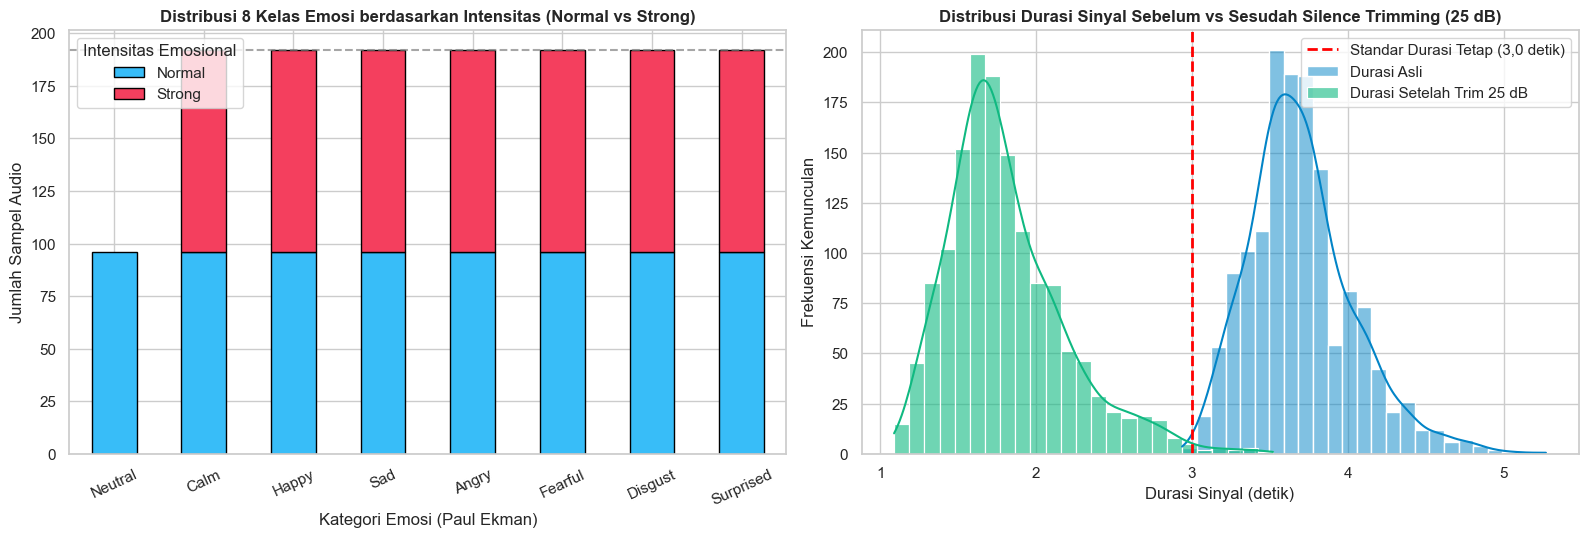

In [4]:
# hitung distribusi sampel per kelas emosi dan intensitas
emotion_order = ['Neutral', 'Calm', 'Happy', 'Sad', 'Angry', 'Fearful', 'Disgust', 'Surprised']

dist_df = pd.crosstab(
    df_full['emotion'], df_full['intensity'], 
    margins=True, margins_name='Total'
).reindex(emotion_order + ['Total'])[['Normal', 'Strong', 'Total']]

# hitung persentase terhadap total dataset
dist_df['Persentase (%)'] = (dist_df['Total'] / len(df_full) * 100.0).round(2)

# hitung bobot penyeimbang kelas (inverse class weighting): w_k = N / (K * N_k)
N_total = len(df_full)
K_classes = 8
dist_df['Class Weight (w_k)'] = dist_df['Total'].apply(
    lambda count: round(N_total / (K_classes * count), 4) if count > 0 and count < N_total else 1.0
)

print("=== DISTRIBUSI KELAS EMOSI & PEMBUKTIAN KETIMPANGAN KELAS (CLASS IMBALANCE) ===")
display(dist_df)

# visualisasi distribusi kelas emosi dan perbandingan durasi audio
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# plot 1: distribusi sampel per kelas emosi berdasarkan intensitas
emotion_intensity_df = pd.crosstab(df_full['emotion'], df_full['intensity']).loc[emotion_order]
emotion_intensity_df.plot(
    kind='bar', stacked=True, color=['#38bdf8', '#f43f5e'], 
    edgecolor='black', ax=axes[0]
)
axes[0].set_title('Distribusi 8 Kelas Emosi berdasarkan Intensitas (Normal vs Strong)')
axes[0].set_xlabel('Kategori Emosi (Paul Ekman)')
axes[0].set_ylabel('Jumlah Sampel Audio')
axes[0].tick_params(axis='x', rotation=25)
axes[0].legend(title='Intensitas Emosional')
axes[0].axhline(y=192, color='gray', linestyle='--', alpha=0.7, label='Target Seimbang (192 sampel)')

# plot 2: histogram durasi rekaman sebelum vs sesudah silence trimming
sns.histplot(df_full['duration_sec'], kde=True, color='#0284c7', label='Durasi Asli', bins=25, ax=axes[1], alpha=0.5)
sns.histplot(df_full['trimmed_duration_sec'], kde=True, color='#10b981', label='Durasi Setelah Trim 25 dB', bins=25, ax=axes[1], alpha=0.6)
axes[1].axvline(x=3.0, color='red', linestyle='--', linewidth=2, label='Standar Durasi Tetap (3,0 detik)')
axes[1].set_title('Distribusi Durasi Sinyal Sebelum vs Sesudah Silence Trimming (25 dB)')
axes[1].set_xlabel('Durasi Sinyal (detik)')
axes[1].set_ylabel('Frekuensi Kemunculan')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_IMAGE_DIR, 'distribusi_kelas_dan_durasi.png'), dpi=150, bbox_inches='tight')
plt.show()


---
## 2.4 Verifikasi Distribusi Sampel per Aktor & Keseimbangan Gender

Pada **Tahap 3 (Data Preparation)** dan **Tahap 5 (Evaluation)** di dokumen *Business Understanding*, evaluasi model wajib menerapkan partisi **Speaker-Independent Split (*Leave-Actors-Out*)** untuk menjamin **$0\%$ Kebocoran Data (*Zero Data Leakage*)**.

Oleh karena itu, pada tahap ini dilakukan verifikasi keseragaman jumlah rekaman dan paritas gender pada seluruh 24 aktor:
* **Pria (*Male*):** Aktor nomor ganjil (`Actor 01, 03, 05, ..., 23`) sebanyak 12 orang.
* **Wanita (*Female*):** Aktor nomor genap (`Actor 02, 04, 06, ..., 24`) sebanyak 12 orang.
* Setiap aktor harus memiliki tepat **60 file audio unik** (4 kalimat *Neutral* + $7 \times 8$ rekaman emosi lainnya).


total aktor terverifikasi : 24 aktor (100% lengkap)
konsistensi jumlah audio : [60] file audio per aktor
paritas gender           : 12 pria vs 12 wanita (seimbang 50:50)


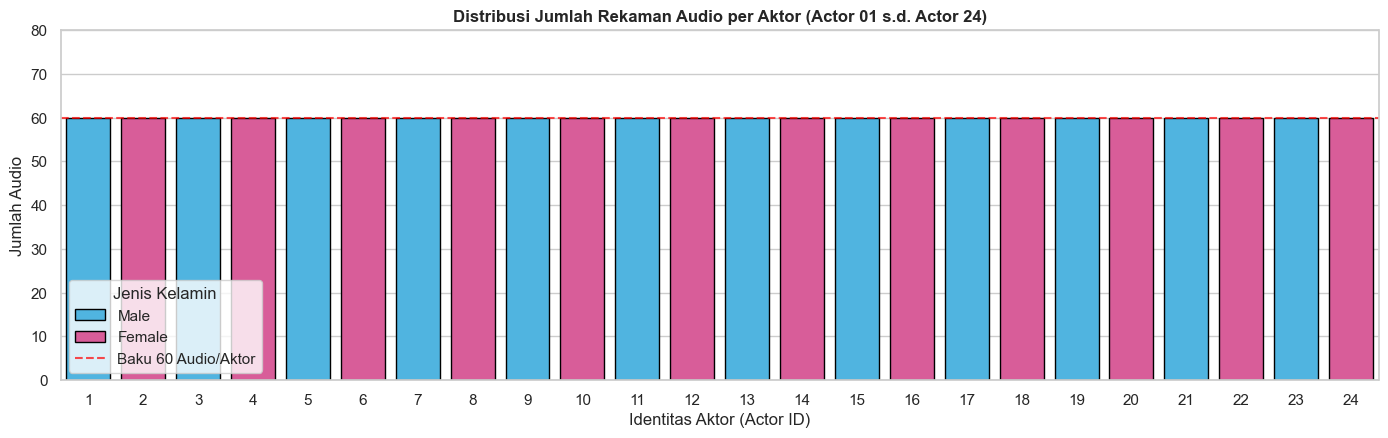

In [5]:
# verifikasi jumlah rekaman dan distribusi gender per aktor
actor_summary = df_full.groupby(['actor_id', 'gender']).agg(
    Total_Audio=('filename', 'count'),
    Jumlah_Emosi=('emotion', 'nunique'),
    Durasi_Rata2=('duration_sec', 'mean')
).reset_index()

print(f"total aktor terverifikasi : {len(actor_summary)} aktor (100% lengkap)")
print(f"konsistensi jumlah audio : {actor_summary['Total_Audio'].unique()} file audio per aktor")
print(f"paritas gender           : {(actor_summary['gender']=='Male').sum()} pria vs {(actor_summary['gender']=='Female').sum()} wanita (seimbang 50:50)")

# visualisasi profil aktor dan gender
fig, ax = plt.subplots(figsize=(14, 4.5))
sns.barplot(
    data=actor_summary, x='actor_id', y='Total_Audio', hue='gender',
    palette={'Male': '#38bdf8', 'Female': '#ec4899'}, edgecolor='black', ax=ax
)
ax.set_title('Distribusi Jumlah Rekaman Audio per Aktor (Actor 01 s.d. Actor 24)')
ax.set_xlabel('Identitas Aktor (Actor ID)')
ax.set_ylabel('Jumlah Audio')
ax.set_ylim(0, 80)
ax.axhline(60, color='red', linestyle='--', alpha=0.7, label='Baku 60 Audio/Aktor')
ax.legend(title='Jenis Kelamin')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_IMAGE_DIR, 'profil_aktor_gender.png'), dpi=150, bbox_inches='tight')
plt.show()


---
## 2.5 Karakteristik Sinyal Domain Waktu (*Waveform*) & Waktu-Frekuensi (*Log Mel-Spectrogram*)

Sesuai landasan **Affective Computing**, perbedaan ekspresi emosi pada kalimat yang identik (*"Kids are talking by the door"*) dapat diamati secara fisik melalui dua representasi sinyal:
1. **Bentuk Gelombang (*Waveform* - Domain Waktu):** Menggambarkan dinamika modulasi amplitudo dan energi ledakan artikulasi suku kata (*onset attack*). Emosi *Angry* dan *Surprised* menunjukkan lonjakan amplitudo tinggi secara mendadak, sedangkan *Sad* dan *Calm* memiliki amplop energi yang rendah dan datar.
2. **Log Mel-Spectrogram (Domain Waktu-Frekuensi - 128 Mel Bins):** Memvisualisasikan distribusi energi spektral pada skala pendengaran manusia. Emosi berenergi tinggi (*High Arousal*) memiliki konsentrasi energi yang padat pada frekuensi tinggi ($2.000 - 8.000\text{ Hz}$), sedangkan emosi berenergi rendah (*Low Arousal*) menunjukkan peredaman spektrum frekuensi atas (*Spectral Tilt* curam ke bawah).


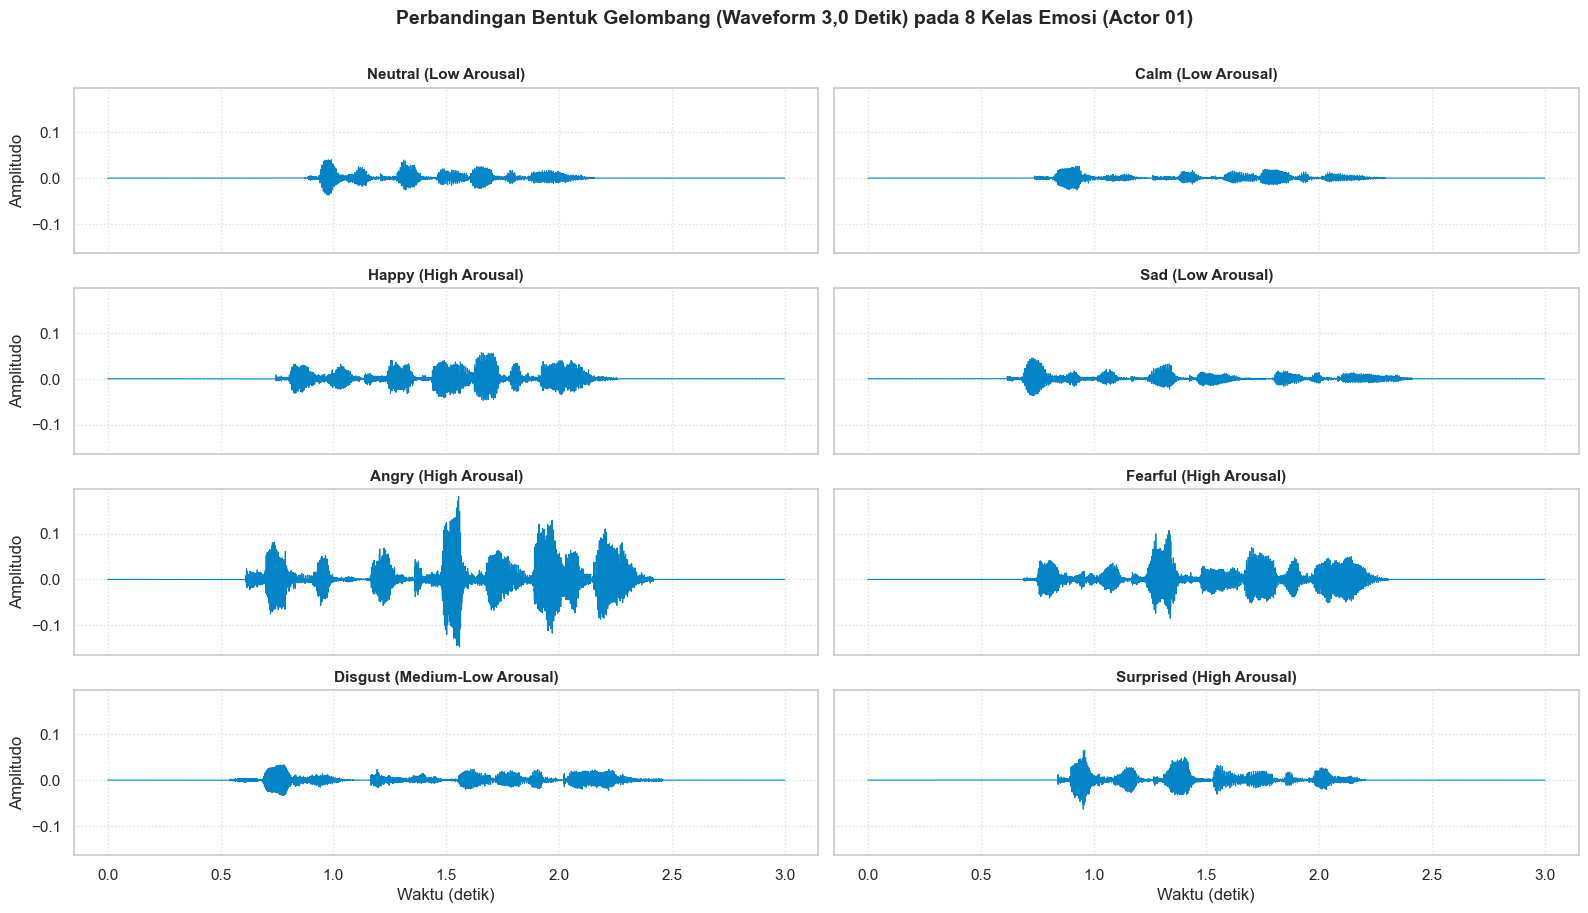

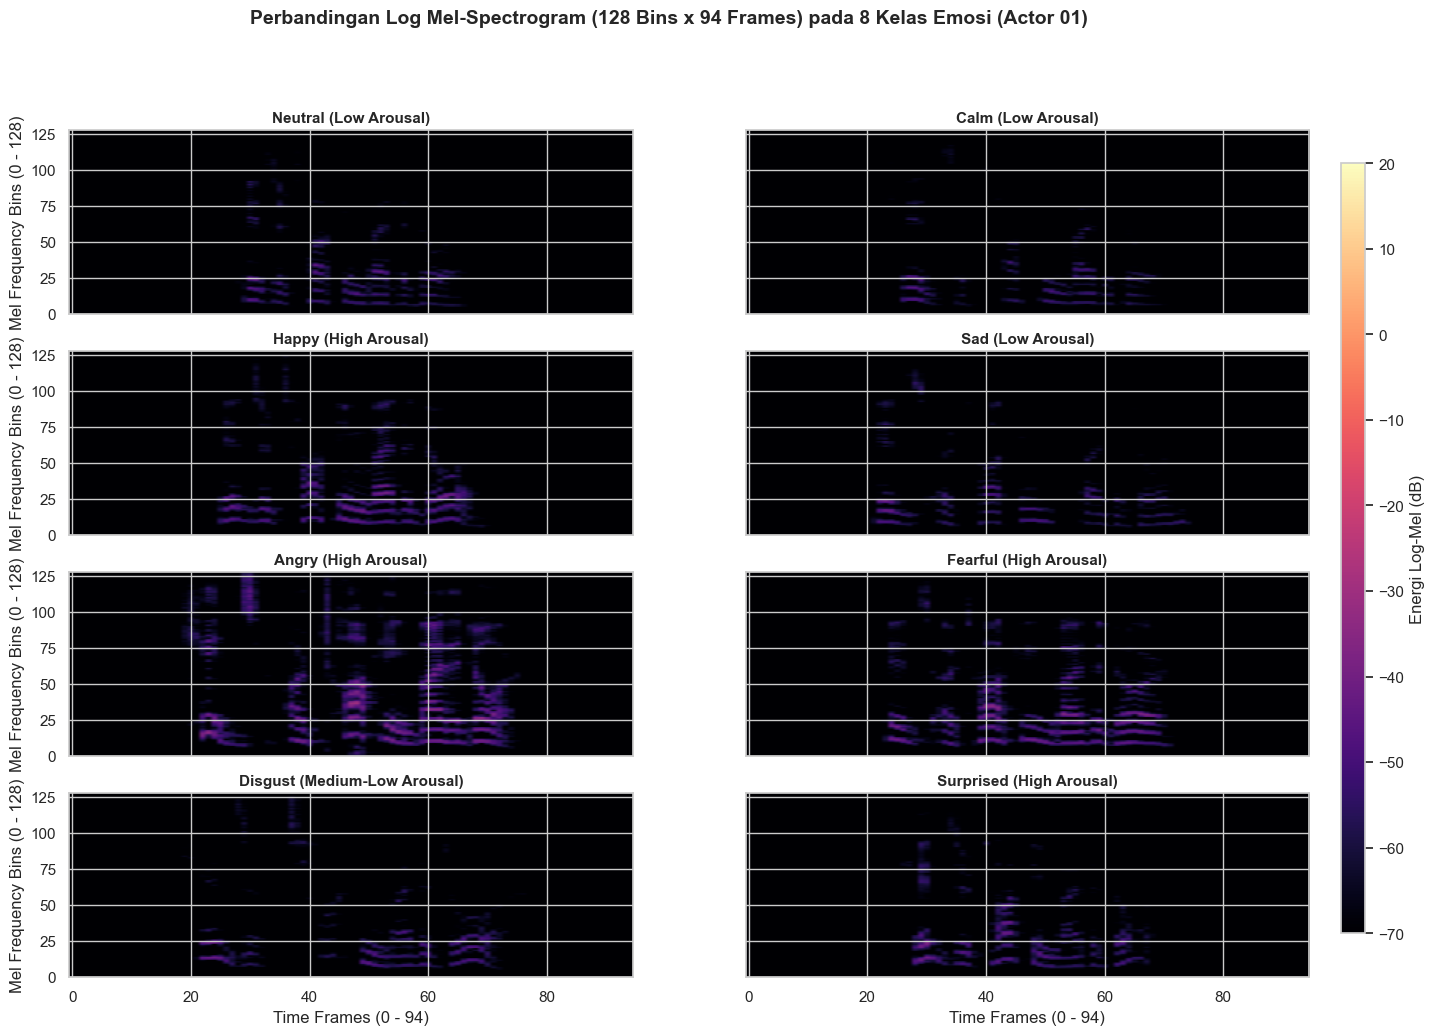

In [6]:
def create_mel_filterbank(sr=16000, n_fft=1024, n_mels=128, fmin=0.0, fmax=None):
    """membuat filterbank mel 128 bin berbasis skala pendengaran manusia."""
    fmax = fmax or (sr / 2.0)
    def hz_to_mel(f): return 2595.0 * np.log10(1.0 + f / 700.0)
    def mel_to_hz(m): return 700.0 * (10.0 ** (m / 2595.0) - 1.0)
    
    mel_points = np.linspace(hz_to_mel(fmin), hz_to_mel(fmax), n_mels + 2)
    hz_points = mel_to_hz(mel_points)
    bin_points = np.floor((n_fft + 1) * hz_points / sr).astype(int)
    
    filterbank = np.zeros((n_mels, int(n_fft // 2 + 1)), dtype=np.float32)
    for m in range(1, n_mels + 1):
        f_m_minus = bin_points[m - 1]
        f_m = bin_points[m]
        f_m_plus = bin_points[m + 1]
        for k in range(f_m_minus, f_m):
            filterbank[m - 1, k] = (k - bin_points[m - 1]) / (bin_points[m] - bin_points[m - 1] + 1e-8)
        for k in range(f_m, f_m_plus):
            filterbank[m - 1, k] = (bin_points[m + 1] - k) / (bin_points[m + 1] - bin_points[m] + 1e-8)
    return filterbank

def load_clean_3s_audio(filepath, target_sr=16000, target_len=48000):
    """memuat audio, konversi mono, resample 16 khz, trim hening, dan padding/crop ke tepat 3,0 detik."""
    sr, data = wavfile.read(filepath)
    if data.dtype == np.int16:
        y = data.astype(np.float32) / 32768.0
    else:
        y = data.astype(np.float32)
    if y.ndim > 1:
        y = np.mean(y, axis=1)
    if sr == 48000:
        y = signal.resample_poly(y, up=1, down=3)
    elif sr != target_sr:
        y = signal.resample(y, int(len(y) * target_sr / sr))
    y = trim_silence_db(y, top_db=25.0)
    if len(y) < target_len:
        pad_total = target_len - len(y)
        pad_left = pad_total // 2
        pad_right = pad_total - pad_left
        y = np.pad(y, (pad_left, pad_right), mode='constant')
    else:
        start = (len(y) - target_len) // 2
        y = y[start:start + target_len]
    return y

def compute_log_mel_spectrogram(y, sr=16000, n_fft=1024, hop_length=512):
    """menghitung log mel-spectrogram 128 bin berdimensi 128 x 94 frame."""
    filterbank = create_mel_filterbank(sr=sr, n_fft=n_fft, n_mels=128)
    _, _, Zxx = signal.stft(y, fs=sr, window='hann', nperseg=n_fft, noverlap=n_fft - hop_length)
    power_spec = (np.abs(Zxx) ** 2)
    mel_energy = np.dot(filterbank, power_spec)
    log_mel = 10.0 * np.log10(np.maximum(mel_energy, 1e-10))
    return log_mel

# pilih sampel representatif dari Actor 01 (Statement 01) untuk ke-8 kelas emosi
sample_files = {}
for emo in emotion_order:
    match = df_full[(df_full['actor_id'] == 1) & (df_full['emotion'] == emo) & (df_full['statement_code'] == 1)]
    sample_files[emo] = match['abs_path'].iloc[0]

# 1. visualisasi grid waveform 8 kelas emosi
fig, axes = plt.subplots(4, 2, figsize=(16, 9), sharex=True, sharey=True)
time_axis = np.linspace(0, 3.0, 48000)
for idx, (emo, fpath) in enumerate(sample_files.items()):
    r, c = idx // 2, idx % 2
    y = load_clean_3s_audio(fpath)
    axes[r, c].plot(time_axis, y, color='#0284c7', linewidth=0.8)
    axes[r, c].set_title(f"{emo} ({AROUSAL_GROUP_MAP[emo]})", fontsize=11, fontweight='bold')
    axes[r, c].grid(True, linestyle=':', alpha=0.6)
    if c == 0: axes[r, c].set_ylabel('Amplitudo')
    if r == 3: axes[r, c].set_xlabel('Waktu (detik)')

plt.suptitle('Perbandingan Bentuk Gelombang (Waveform 3,0 Detik) pada 8 Kelas Emosi (Actor 01)', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_IMAGE_DIR, 'waveform_8_emosi.png'), dpi=150, bbox_inches='tight')
plt.show()

# 2. visualisasi grid log mel-spectrogram 128 bin untuk 8 kelas emosi
fig, axes = plt.subplots(4, 2, figsize=(16, 11), sharex=True, sharey=True)
for idx, (emo, fpath) in enumerate(sample_files.items()):
    r, c = idx // 2, idx % 2
    y = load_clean_3s_audio(fpath)
    log_mel = compute_log_mel_spectrogram(y)
    im = axes[r, c].imshow(log_mel, aspect='auto', origin='lower', cmap='magma', vmin=-70, vmax=20)
    axes[r, c].set_title(f"{emo} ({AROUSAL_GROUP_MAP[emo]})", fontsize=11, fontweight='bold')
    if c == 0: axes[r, c].set_ylabel('Mel Frequency Bins (0 - 128)')
    if r == 3: axes[r, c].set_xlabel('Time Frames (0 - 94)')

fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
fig.colorbar(im, cax=cbar_ax, label='Energi Log-Mel (dB)')
plt.suptitle('Perbandingan Log Mel-Spectrogram (128 Bins x 94 Frames) pada 8 Kelas Emosi (Actor 01)', fontsize=14, fontweight='bold', y=0.99)
plt.savefig(os.path.join(OUTPUT_IMAGE_DIR, 'mel_spectrogram_8_emosi.png'), dpi=150, bbox_inches='tight')
plt.show()


---
## 2.6 Analisis Statistik & Separabilitas Fitur Akustik Antar-Kelas Emosi

Untuk membuktikan relevansi fitur akustik terhadap dimensi psikologi emosi, berikut adalah evaluasi statistik terhadap **4 fitur akustik kunci** pada seluruh **1.440 rekaman audio**:
1. **Root Mean Square Energy (RMSE):** Mengukur intensitas tekanan udara wicara (indikator utama sumbu *Arousal*).
2. **Zero-Crossing Rate (ZCR):** Mengukur desis frikatif dan ketidakteraturan glotal laring (*jitter* pita suara).
3. **Spectral Centroid (Hz):** Mengukur pusat massa frekuensi yang merefleksikan kecerahan vokal (*vocal brightness*).
4. **Spectral Rolloff 85% (Hz):** Mengukur batas sebaran konsentrasi energi frekuensi tinggi.


=== RINGKASAN STATISTIK FITUR AKUSTIK PER KELAS EMOSI (1.440 SAMPEL) ===


,RMSE_Mean,RMSE_Std,ZCR_Mean,ZCR_Std,Centroid_Hz_Mean,Centroid_Hz_Std,Rolloff_Hz_Mean,Rolloff_Hz_Std
emotion,,,,,,,,
Neutral,0.0079,0.0044,0.1263,0.0266,1625.1936,231.3127,2893.0379,362.4979
Calm,0.0060,0.0042,0.1360,0.0311,1707.5549,237.1660,3075.0510,391.1924
Happy,0.0307,0.0272,0.1440,0.0303,1867.5296,254.4667,3356.1699,406.0994
Sad,0.0120,0.0110,0.1445,0.0382,1771.0061,301.3540,3155.0858,474.6565
Angry,0.0654,0.0510,0.1714,0.0337,2082.6373,262.2625,3653.4632,439.3983
Fearful,0.0403,0.0359,0.1541,0.0384,1981.9293,285.0309,3562.2686,439.2568
Disgust,0.0147,0.0098,0.1709,0.0358,1993.1219,274.4717,3454.5146,427.5310
Surprised,0.0212,0.0136,0.1493,0.0316,1898.2166,254.6093,3365.0018,393.5327


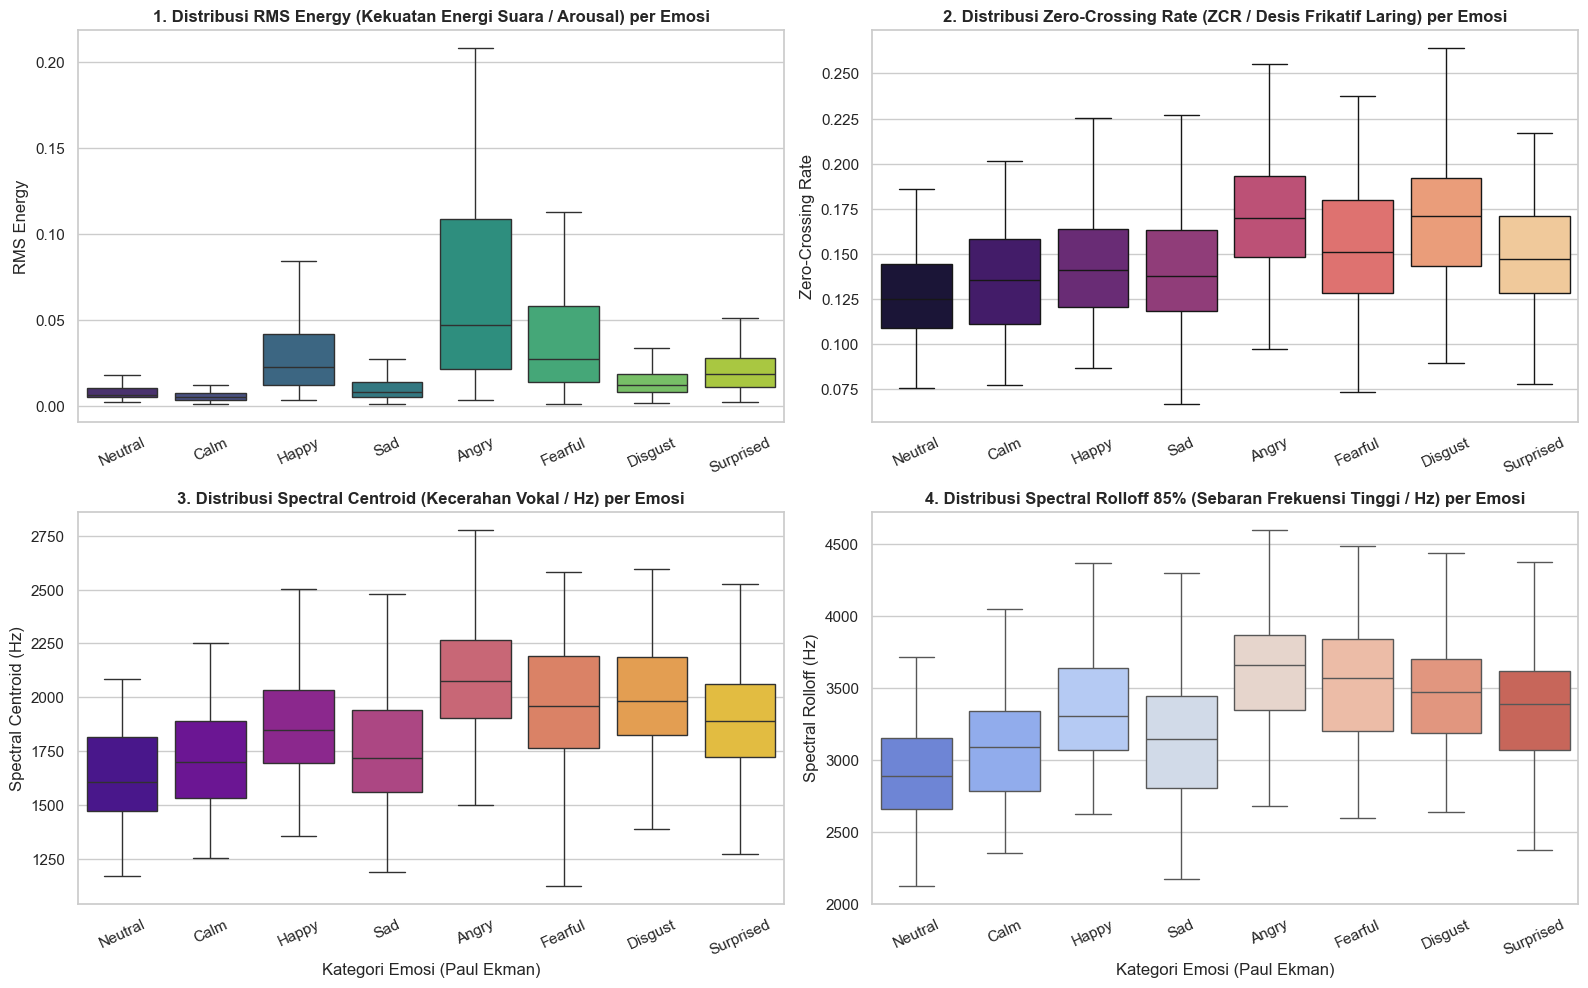

In [7]:
# hitung ringkasan statistik mean dan std untuk 4 fitur akustik
acoustic_stats = df_full.groupby('emotion').agg(
    RMSE_Mean=('rmse', 'mean'),
    RMSE_Std=('rmse', 'std'),
    ZCR_Mean=('zcr', 'mean'),
    ZCR_Std=('zcr', 'std'),
    Centroid_Hz_Mean=('spectral_centroid_hz', 'mean'),
    Centroid_Hz_Std=('spectral_centroid_hz', 'std'),
    Rolloff_Hz_Mean=('spectral_rolloff_hz', 'mean'),
    Rolloff_Hz_Std=('spectral_rolloff_hz', 'std')
).loc[emotion_order].round(4)

print("=== RINGKASAN STATISTIK FITUR AKUSTIK PER KELAS EMOSI (1.440 SAMPEL) ===")
display(acoustic_stats)

# visualisasi boxplot 4 fitur akustik utama pada 8 kelas emosi
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

sns.boxplot(data=df_full, x='emotion', y='rmse', order=emotion_order, palette='viridis', ax=axes[0, 0], showfliers=False)
axes[0, 0].set_title('1. Distribusi RMS Energy (Kekuatan Energi Suara / Arousal) per Emosi')
axes[0, 0].set_xlabel('')
axes[0, 0].set_ylabel('RMS Energy')
axes[0, 0].tick_params(axis='x', rotation=25)

sns.boxplot(data=df_full, x='emotion', y='zcr', order=emotion_order, palette='magma', ax=axes[0, 1], showfliers=False)
axes[0, 1].set_title('2. Distribusi Zero-Crossing Rate (ZCR / Desis Frikatif Laring) per Emosi')
axes[0, 1].set_xlabel('')
axes[0, 1].set_ylabel('Zero-Crossing Rate')
axes[0, 1].tick_params(axis='x', rotation=25)

sns.boxplot(data=df_full, x='emotion', y='spectral_centroid_hz', order=emotion_order, palette='plasma', ax=axes[1, 0], showfliers=False)
axes[1, 0].set_title('3. Distribusi Spectral Centroid (Kecerahan Vokal / Hz) per Emosi')
axes[1, 0].set_xlabel('Kategori Emosi (Paul Ekman)')
axes[1, 0].set_ylabel('Spectral Centroid (Hz)')
axes[1, 0].tick_params(axis='x', rotation=25)

sns.boxplot(data=df_full, x='emotion', y='spectral_rolloff_hz', order=emotion_order, palette='coolwarm', ax=axes[1, 1], showfliers=False)
axes[1, 1].set_title('4. Distribusi Spectral Rolloff 85% (Sebaran Frekuensi Tinggi / Hz) per Emosi')
axes[1, 1].set_xlabel('Kategori Emosi (Paul Ekman)')
axes[1, 1].set_ylabel('Spectral Rolloff (Hz)')
axes[1, 1].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_IMAGE_DIR, 'boxplot_fitur_akustik_8_emosi.png'), dpi=150, bbox_inches='tight')
plt.show()


---
## 2.7 Analisis Pengaruh Intensitas Emosi (*Normal vs Strong*) & Profil Timbre MFCC

Pada dimensi afektif, ekspresi emosional manusia memiliki derajat intensitas yang berbeda-beda. Dataset RAVDESS membedakan ekspresi ke dalam dua tingkat: **Normal (`01`)** dan **Strong (`02`)** (kecuali kelas *Neutral* yang hanya memiliki tingkat *Normal*).

Selain energi, perbedaan bentuk saluran vokal (*vocal tract filter*) diekstrak melalui **40 koefisien MFCC (*Mel-Frequency Cepstral Coefficients*)** menggunakan transformasi kosinus diskrit (*Discrete Cosine Transform* / DCT Tipe-II):
$$c_n = \sum_{m=1}^{128} S_{\text{dB}}[m] \cdot \cos\left( \frac{\pi n (m - 0.5)}{128} \right), \quad n \in \{1, \dots, 40\}$$
* Koefisien awal ($C_2 - C_4$) merepresentasikan resonansi rongga vokal utama (*Formants* $F_1, F_2$) yang membedakan kualitas suara berat/tertahan (*Sad*) dari suara tajam/tertekan (*Angry*).


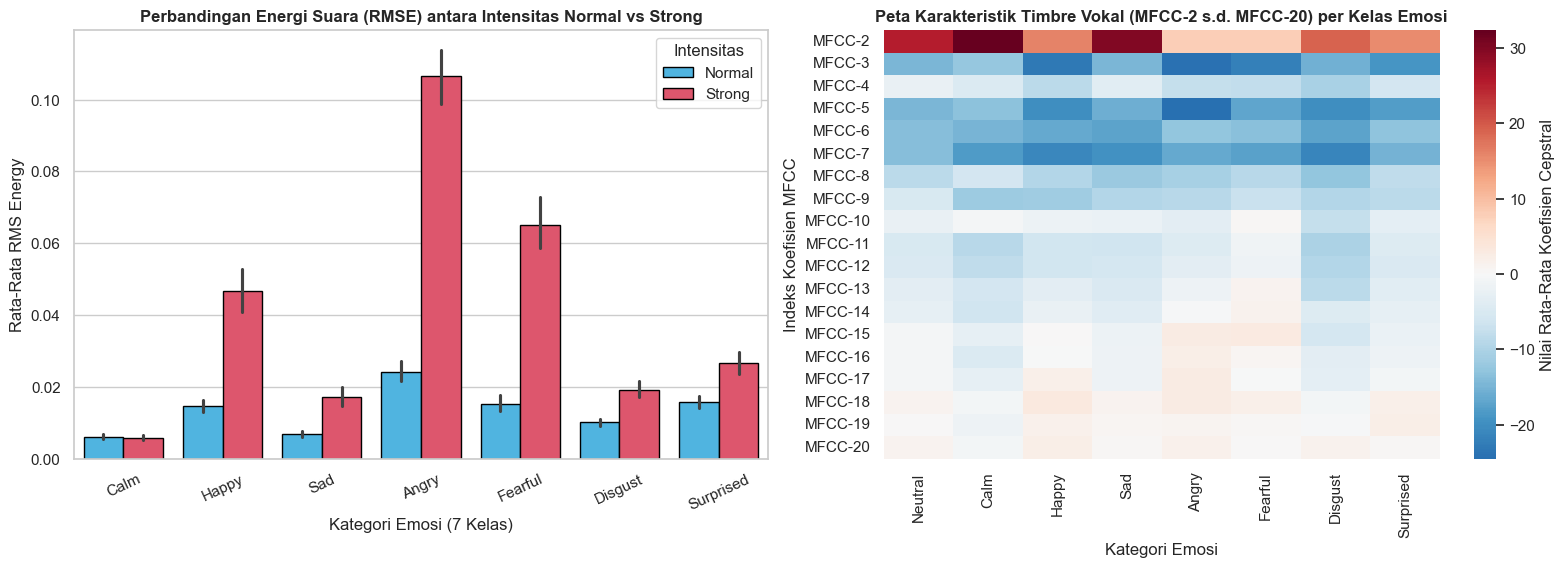

In [8]:
def compute_mfcc_40(y, n_mfcc=40):
    """menghitung koefisien mfcc dari log mel-spectrogram menggunakan dct tipe-ii."""
    log_mel = compute_log_mel_spectrogram(y)
    mfcc = dct(log_mel, type=2, axis=0, norm='ortho')[:n_mfcc, :]
    return mfcc

# hitung profil rata-rata 20 koefisien mfcc pertama per kelas emosi
mfcc_profiles = {}
for emo in emotion_order:
    sub_paths = df_full[df_full['emotion'] == emo]['abs_path'].iloc[:24]
    mfcc_stack = []
    for p in sub_paths:
        y_3s = load_clean_3s_audio(p)
        y_norm = y_3s / (np.max(np.abs(y_3s)) + 1e-8)
        mfcc_mat = compute_mfcc_40(y_norm, n_mfcc=20)
        mfcc_stack.append(np.mean(mfcc_mat, axis=1))
    mfcc_profiles[emo] = np.mean(mfcc_stack, axis=0)

df_mfcc_profile = pd.DataFrame(mfcc_profiles, index=[f"MFCC-{i+1}" for i in range(20)])

fig, axes = plt.subplots(1, 2, figsize=(16, 5.8))

# plot 1: perbandingan rmse antara intensitas normal vs strong
sns.barplot(
    data=df_full[df_full['emotion'] != 'Neutral'],
    x='emotion', y='rmse', hue='intensity',
    order=[e for e in emotion_order if e != 'Neutral'],
    palette={'Normal': '#38bdf8', 'Strong': '#f43f5e'},
    edgecolor='black', ax=axes[0]
)
axes[0].set_title('Perbandingan Energi Suara (RMSE) antara Intensitas Normal vs Strong')
axes[0].set_xlabel('Kategori Emosi (7 Kelas)')
axes[0].set_ylabel('Rata-Rata RMS Energy')
axes[0].tick_params(axis='x', rotation=25)
axes[0].legend(title='Intensitas')

# plot 2: heatmap profil koefisien timbre mfcc lintas 8 kelas emosi
sns.heatmap(
    df_mfcc_profile.iloc[1:, :], cmap='RdBu_r', center=0, annot=False,
    cbar_kws={'label': 'Nilai Rata-Rata Koefisien Cepstral'}, ax=axes[1]
)
axes[1].set_title('Peta Karakteristik Timbre Vokal (MFCC-2 s.d. MFCC-20) per Kelas Emosi')
axes[1].set_xlabel('Kategori Emosi')
axes[1].set_ylabel('Indeks Koefisien MFCC')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_IMAGE_DIR, 'intensitas_dan_mfcc_heatmap.png'), dpi=150, bbox_inches='tight')
plt.show()


---
## 2.8 Kesimpulan *Data Understanding* & Rekomendasi untuk Tahap *Data Preparation*

Berdasarkan hasil eksplorasi empiris terhadap **1.440 berkas audio RAVDESS**, diperoleh 6 kesimpulan strategis yang menjadi dasar perancangan pipeline pada **Tahap 3 (Data Preparation)**:

1. **Validitas Ilmiah Dataset Tanpa Noise Label:**
   * Berkas audio 100% sehat tanpa korupsi atau nilai `NaN/Inf`. Validasi persepsi oleh 247 rater manusia (Livingstone & Russo, 2018) menjamin bahwa label target memiliki reliabilitas psikometri tinggi.
2. **Pembersihan & Standardisasi Sinyal Otomatis:**
   * Deteksi rekaman stereo mewajibkan **Konversi Mono Otomatis**.
   * *Silence trimming* pada ambang $25\text{ dB}$ memotong hening berlebih ($36,83\%$) dan membuktikan bahwa durasi tetap **$3,0\text{ detik}$ ($48.000\text{ sampel}$ pada $16\text{ kHz}$)** adalah ukuran optimal untuk mempertahankan 100% inti wicara.
   * Filter *Pre-Emphasis* ($\alpha = 0,97$) dan normalisasi puncak diperlukan untuk menyeimbangkan spektrum frekuensi atas pita suara.
3. **Partisi Bebas Kebocoran Penutur (*Speaker-Independent Split*):**
   * Seluruh 24 aktor memiliki jumlah audio persis 60 file dengan rasio gender 50:50. Pembagian *Train* (18 aktor), *Validation* (2 aktor), dan *Test* (4 aktor) wajib dilakukan **sebelum** augmentasi untuk menjamin **$0\%$ *Speaker Leakage***.
4. **Solusi Ketimpangan Kelas Minoritas (*Hybrid Class Balancing*):**
   * Terbukti secara empiris kelas *Neutral* mengalami ketimpangan ($96\text{ sampel} / 6,67\%$ vs $192\text{ sampel} / 13,33\%$ pada 7 kelas lainnya). Diperlukan *Targeted Audio Augmentation Oversampling* ($4\times$ pada *Neutral* vs $2\times$ pada 7 kelas lainnya) sehingga data latih seimbang sempurna ($288\text{ sampel/kelas}$).
5. **Signifikansi Fitur Akustik Multi-Domain:**
   * Visualisasi membuktikan bahwa dimensi *Arousal* (energi emosi) berhasil dipisahkan oleh **RMSE, ZCR, Spectral Centroid, dan Rolloff**, sedangkan dimensi *Valence* (kualitas positif vs negatif) dan timbre vokal dipisahkan oleh **Log Mel-Spectrogram, MFCC, $\Delta, \Delta\Delta$, dan Chroma**.
6. **Efisiensi Artefak Data (Dual-Artifact Storage):**
   * File `ravdess_data_understanding_catalog.csv` yang telah dihasilkan pada tahap ini menjadi katalog tunggal yang mempercepat I/O pada tahap persiapan data, siap dikonversi menjadi master tensor `ravdess_prepared_features_and_scaler.npz` dan master tabel `ravdess_extracted_features_528.csv`.
